# Sector Distribution & Statistical Significance of Cyber Incidents in Germany

This notebook analyzes whether the number of documented cyber incidents in Germany **differs statistically significantly across target sectors** (for example, whether **`Public Administration`** differs significantly from other sectors). It compares three complementary views of German cyber incident data:

1. **UMD Raw Data (`umd_cyber_events.xlsx`)** — Filtered to Germany (`country == "Germany"` or `country_iso3 == "DEU"`), using UMD's original NAICS `industry` classification (`Undetermined` excluded when calculating sector shares).
2. **UMD Normalized (`germany_large_incidents.csv`, `source` contains `"UMD"`)** — The same UMD incidents after project harmonization into **10 standardized target sectors**.
3. **Complete Combined Dataset (`germany_large_incidents.csv`, all 4 sources)** — All deduplicated German incidents across *UMD, EuRepoC, KonBriefing,* and *Ransomware.live* mapped to the **10 standardized target sectors**.

### Year-Selection Strategy
- **Excluded incomplete / sparse edge years:** `2026` is a partial year (still ongoing), and pre-`2014` years (`2006–2013`) appear only sparsely in `EuRepoC`/`germany_large_incidents.csv` (`UMD` starts in `2014`).
- **Baseline full window (`2014–2025`, 12 complete years):** Covers every full calendar year where UMD and the combined dataset overlap cleanly.
- **Focused modern window (`2021–2025`, 5 complete years):** Isolates the modern multi-source reporting era after *KonBriefing* started (`2021`) and *Ransomware.live* scaled (`92%` of sector-known combined incidents occur here).

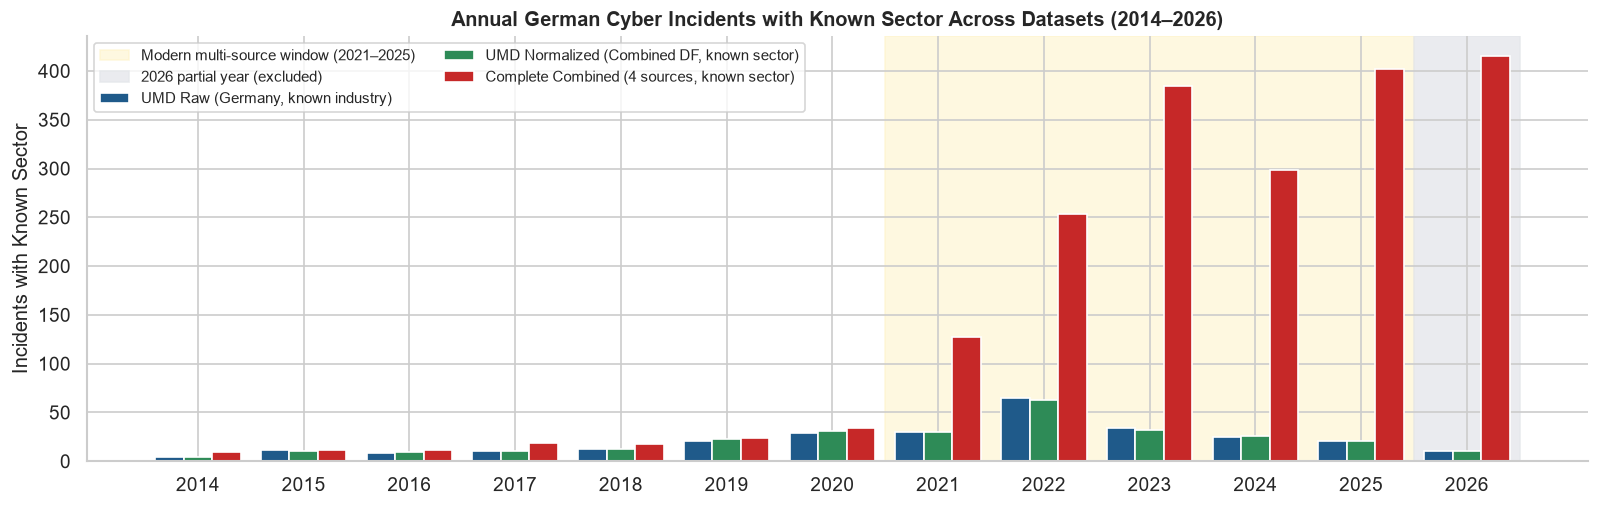

2014–2025 totals (known sector): UMD Raw = 271 (281 total DE UMD incl. Undetermined) | UMD Normalized = 272 | Complete Combined = 1,592 (1,465 in 2021–2025)


In [1]:
import pathlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import (
    chisquare,
    friedmanchisquare,
    binomtest,
    false_discovery_control,
)

# Keep charts crisp and suppress non-critical warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.02)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"

# Resolve project directories robustly whether executed from repo root or germany/notebooks
CWD = pathlib.Path.cwd()
if CWD.name == "notebooks":
    GERMANY_DIR = CWD.parent
elif (CWD / "germany").exists():
    GERMANY_DIR = CWD / "germany"
else:
    GERMANY_DIR = CWD

RAW_DIR = GERMANY_DIR / "data" / "raw"
PREP_DIR = GERMANY_DIR / "data" / "prepared"

# Analysis year windows
YEARS_FULL = list(range(2014, 2026))    # 12 complete calendar years (excludes incomplete 2026)
YEARS_MODERN = list(range(2021, 2026))  # 5 full multi-source years (KonBriefing + Ransomware.live active)

# 1) Load raw UMD dataset and filter to Germany
umd_raw_all = pd.read_excel(RAW_DIR / "umd_cyber_events.xlsx")
umd_de_all = umd_raw_all[
    (umd_raw_all["country"] == "Germany") | (umd_raw_all["country_iso3"] == "DEU")
].copy()
# Drop missing / "Undetermined" industry tags for sector distribution & tests (keep counts transparent)
umd_raw_known = umd_de_all[
    umd_de_all["industry"].notna() & (umd_de_all["industry"] != "Undetermined")
].copy()

# 2) Load deduplicated combined German dataset and extract UMD-normalized slice
comb_all = pd.read_csv(PREP_DIR / "germany_large_incidents.csv")
comb_known = comb_all[comb_all["sector"].notna()].copy()
umd_norm_known = comb_known[comb_known["source"].astype(str).str.contains("UMD", na=False)].copy()

# Concise readable display labels for long UMD NAICS names (kept exact in summary tables)
SHORT_NAICS = {
    "Public Administration": "Public Administration",
    "Manufacturing": "Manufacturing",
    "Professional, Scientific, and Technical Services": "Prof., Sci. & Tech. Services",
    "Information": "Information",
    "Other Services (except Public Administration)": "Other Services (ex. Pub. Admin.)",
    "Finance and Insurance": "Finance & Insurance",
    "Transportation and Warehousing": "Transportation & Warehousing",
    "Educational Services": "Educational Services",
    "Utilities": "Utilities",
    "Health Care and Social Assistance": "Health Care & Social Assistance",
    "Accommodation and Food Services": "Accommodation & Food",
    "Retail Trade": "Retail Trade",
    "Wholesale Trade": "Wholesale Trade",
    "Arts, Entertainment, and Recreation": "Arts & Recreation",
    "Construction": "Construction",
    "Administrative and Support and Waste Management and Remediation Services": "Admin. & Waste Services",
    "Management of Companies and Enterprises": "Management of Companies",
    "Mining, Quarrying, and Oil and Gas Extraction": "Mining & Extraction",
    "Real Estate and Rental and Leasing": "Real Estate & Leasing",
}

SHORT_NORM = {
    "Manufacturing & Industry": "Manufacturing & Industry",
    "Public Administration & Government": "Public Admin & Gov",
    "Retail, Trade & Services": "Retail, Trade & Services",
    "IT & Telecommunications": "IT & Telecom",
    "Finance & Insurance": "Finance & Insurance",
    "Education & Research": "Education & Research",
    "Healthcare": "Healthcare",
    "Energy & Utilities": "Energy & Utilities",
    "Media, NGOs & Other": "Media, NGOs & Other",
    "Transportation & Logistics": "Transport & Logistics",
}


def shorten(label, mapping=None):
    """Map verbose industry/sector strings to compact chart labels while preserving unknowns."""
    if mapping and label in mapping:
        return mapping[label]
    return label


def build_sector_summary(df, sector_col, years, sectors=None):
    """Build total counts, % shares, annual percentiles (p25/p50/p75), and Year x Sector pivots."""
    sub = df[df["year"].isin(years)].copy()
    vc = sub[sector_col].value_counts()
    if sectors is not None:
        vc = vc.reindex(sectors, fill_value=0).sort_values(ascending=False)
    active_sectors = list(vc.index)
    sub = sub[sub[sector_col].isin(active_sectors)]

    # Build Year x Sector annual incident count matrix (0 for years with no reported hits)
    id_col = "incident_id" if "incident_id" in sub.columns else "slug"
    piv_counts = (
        sub.pivot_table(index="year", columns=sector_col, values=id_col, aggfunc="count", fill_value=0)
        .reindex(index=years, columns=active_sectors, fill_value=0)
    )
    # Within each year, normalize counts to % share (0% if a year has 0 incidents overall)
    row_sums = piv_counts.sum(axis=1).replace(0, np.nan)
    piv_pct = piv_counts.div(row_sums, axis=0).fillna(0.0) * 100.0

    total_n = int(vc.sum())
    rows = []
    cum_pct = 0.0
    for sec in active_sectors:
        cnt = int(vc[sec])
        share = (cnt / total_n * 100.0) if total_n > 0 else 0.0
        cum_pct += share
        ann_c = piv_counts[sec].to_numpy()
        ann_p = piv_pct[sec].to_numpy()
        rows.append(
            {
                "Sector": sec,
                "Incidents": cnt,
                "Share (%)": round(share, 1),
                "Cumulative (%)": round(cum_pct, 1),
                "Annual Mean": round(float(np.mean(ann_c)), 2),
                "Annual Median (p50)": round(float(np.percentile(ann_c, 50)), 1),
                "Annual p25–p75": f"{np.percentile(ann_c, 25):.1f} – {np.percentile(ann_c, 75):.1f}",
                "Annual Share % Median (p25–p75)": (
                    f"{np.percentile(ann_p, 50):.1f}% ({np.percentile(ann_p, 25):.1f}–{np.percentile(ann_p, 75):.1f}%)"
                ),
            }
        )
    summary_df = pd.DataFrame(rows).set_index("Sector")
    return vc, piv_counts, piv_pct, summary_df


def plot_sector_distribution(df, sector_col, years, title_prefix, bar_color="#1f5a8a", top_n=None, label_map=None):
    """Plot left bar chart (counts + % share) and right Year x Sector annual % share heatmap."""
    sub = df[df["year"].isin(years)].copy()
    vc_all = sub[sector_col].value_counts()
    if top_n is not None and len(vc_all) > top_n:
        selected_sectors = list(vc_all.head(top_n).index)
        subset_note = f"Top {top_n} of {len(vc_all)} sectors = {int(vc_all.head(top_n).sum()):,}/{int(vc_all.sum()):,} ({vc_all.head(top_n).sum()/vc_all.sum()*100:.1f}%)"
    else:
        selected_sectors = list(vc_all.index)
        subset_note = f"All {len(selected_sectors)} sectors (N = {int(vc_all.sum()):,})"

    vc, piv_counts, piv_pct, summary_df = build_sector_summary(df, sector_col, years, sectors=selected_sectors)
    total_n = int(vc.sum())
    k_sec = len(vc)
    labels_short = [shorten(s, label_map) for s in vc.index]

    fig, (ax_bar, ax_hm) = plt.subplots(
        1, 2, figsize=(17.2, max(5.6, 0.50 * k_sec + 1.4)), gridspec_kw={"width_ratios": [1.0, 1.28]}
    )

    # Left panel: horizontal count + % bar chart sorted descending (top at top)
    y_pos = np.arange(k_sec)
    counts = vc.values
    pcts = counts / total_n * 100.0
    # Highlight Public Administration visually so the focus sector pops cleanly
    colors = [
        "#c62828" if s.startswith("Public Administration") else bar_color for s in vc.index
    ]
    ax_bar.barh(y_pos, counts, color=colors, edgecolor="white", linewidth=0.8, alpha=0.92)
    ax_bar.set_yticks(y_pos)
    ax_bar.set_yticklabels(labels_short, fontsize=10)
    ax_bar.invert_yaxis()
    ax_bar.set_xlim(0, counts.max() * 1.32)
    for idx, (cnt, pct) in enumerate(zip(counts, pcts)):
        ax_bar.text(
            cnt + counts.max() * 0.018,
            idx,
            f"{cnt} ({pct:.1f}%)",
            va="center",
            ha="left",
            fontsize=9.4,
            fontweight="bold" if vc.index[idx].startswith("Public Administration") else "normal",
        )
    # Uniform equal-share reference line (total_n / K)
    equal_cnt = total_n / k_sec
    ax_bar.axvline(equal_cnt, color="#444444", linestyle="--", linewidth=1.3)
    ax_bar.text(
        equal_cnt,
        k_sec - 0.15,
        f" Equal share ({100/k_sec:.1f}% = {equal_cnt:.1f})",
        fontsize=8.6,
        color="#333333",
        ha="left",
        va="bottom",
    )
    ax_bar.set_xlabel("Documented Incidents")
    ax_bar.set_title("Total Counts & Share (%)", fontsize=11.5, pad=8)
    ax_bar.spines[["top", "right"]].set_visible(False)

    # Right panel: Sector (rows) x Year (cols) % share heatmap matching the bar sort order
    hm_data = piv_pct.T.loc[vc.index]
    ax_hm.grid(False)
    im = ax_hm.imshow(hm_data.values, cmap="YlGnBu", vmin=0, vmax=max(45.0, float(hm_data.values.max())), aspect="auto")
    ax_hm.set_xticks(range(len(years)))
    ax_hm.set_xticklabels([str(y) for y in years], fontsize=9.5)
    ax_hm.set_yticks(range(k_sec))
    ax_hm.set_yticklabels(["" for _ in labels_short])  # Aligned with left y-axis
    for i in range(k_sec):
        for j in range(len(years)):
            val = hm_data.iloc[i, j]
            cnt_cell = int(piv_counts.T.loc[vc.index].iloc[i, j])
            txt = f"{val:.0f}%" if cnt_cell > 0 else "0"
            ax_hm.text(
                j,
                i,
                txt,
                ha="center",
                va="center",
                fontsize=8.4,
                color="white" if val >= 28 else ("#888888" if cnt_cell == 0 else "black"),
            )
    ax_hm.set_xlabel("Year")
    ax_hm.set_title("Annual Sector Share (% of Year's Incidents; '0' = zero hits)", fontsize=11.5, pad=8)
    cbar = fig.colorbar(im, ax=ax_hm, shrink=0.82, pad=0.025)
    cbar.set_label("Share of annual incidents (%)", fontsize=9.5)
    ax_hm.tick_params(length=0)

    fig.suptitle(f"{title_prefix}  —  {subset_note}", fontsize=13.0, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()
    return summary_df


# Print overall coverage & plot yearly comparison across datasets (2014-2026)
yr_range_plot = list(range(2014, 2027))
yr_comp = pd.DataFrame(
    {
        "UMD Raw (known industry)": umd_raw_known[umd_raw_known["year"].isin(yr_range_plot)].groupby("year").size(),
        "UMD Normalized (known sector)": umd_norm_known[umd_norm_known["year"].isin(yr_range_plot)].groupby("year").size(),
        "Complete Combined (known sector)": comb_known[comb_known["year"].isin(yr_range_plot)].groupby("year").size(),
    }
).reindex(yr_range_plot, fill_value=0)

fig, ax = plt.subplots(figsize=(13.5, 4.4))
x = np.arange(len(yr_range_plot))
w = 0.27
ax.bar(x - w, yr_comp["UMD Raw (known industry)"], width=w, color="#1f5a8a", label="UMD Raw (Germany, known industry)")
ax.bar(x, yr_comp["UMD Normalized (known sector)"], width=w, color="#2e8b57", label="UMD Normalized (Combined DF, known sector)")
ax.bar(x + w, yr_comp["Complete Combined (known sector)"], width=w, color="#c62828", label="Complete Combined (4 sources, known sector)")
ax.axvspan(6.5, 11.5, color="#fef3c7", alpha=0.55, zorder=0, label="Modern multi-source window (2021–2025)")
ax.axvspan(11.5, 12.5, color="#e5e7eb", alpha=0.80, zorder=0, label="2026 partial year (excluded)")
ax.set_xticks(x)
ax.set_xticklabels([str(y) for y in yr_range_plot])
ax.set_ylabel("Incidents with Known Sector")
ax.set_title("Annual German Cyber Incidents with Known Sector Across Datasets (2014–2026)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", fontsize=8.8, ncol=2)
plt.tight_layout()
plt.show()

print(
    f"2014–2025 totals (known sector): "
    f"UMD Raw = {int(yr_comp.loc[YEARS_FULL, 'UMD Raw (known industry)'].sum()):,} "
    f"({umd_de_all['year'].between(2014, 2025).sum()} total DE UMD incl. Undetermined) | "
    f"UMD Normalized = {int(yr_comp.loc[YEARS_FULL, 'UMD Normalized (known sector)'].sum()):,} | "
    f"Complete Combined = {int(yr_comp.loc[YEARS_FULL, 'Complete Combined (known sector)'].sum()):,} "
    f"({int(yr_comp.loc[YEARS_MODERN, 'Complete Combined (known sector)'].sum()):,} in 2021–2025)"
)

---

## 1. UMD Raw Data (`industry` Attribute, Germany Only)

We first inspect **UMD's native NAICS `industry` labels** across Germany's `12` complete years (`2014–2025`, `N = 271` incidents with known industry out of `280`; `9` `Undetermined` and partial `2026` omitted).
- **Why show Top 10 in the chart and all 19 in the table?** The Top 10 NAICS industries capture **`241 / 271` (`88.9%`)** of all sector-attributed German UMD hits; the remaining 9 smaller NAICS categories each have `1–8` incidents across 12 years.
- **`Public Administration` (`48`, `17.7%` of all 19; `19.9%` within Top 10) and `Manufacturing` (`48`, `17.7%`)** tie for #1, each averaging roughly `4` UMD incidents per year—nearly double the equal-share benchmark (`10%` within Top 10, `5.3%` across all 19).

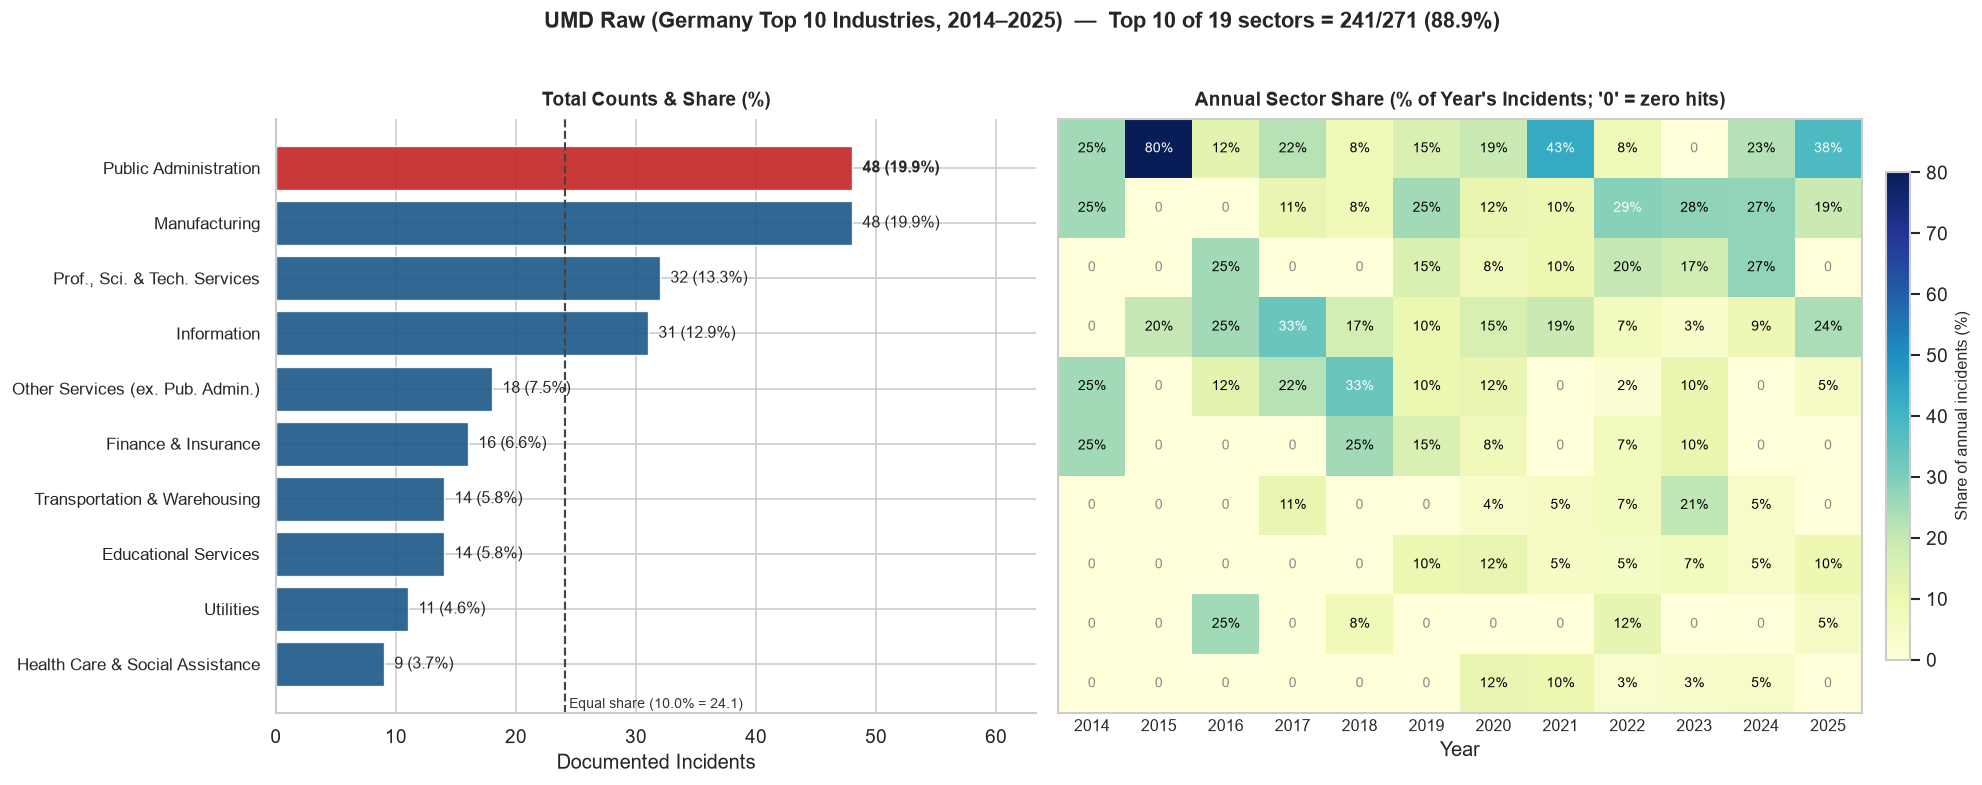

All 19 known UMD NAICS industries in Germany (2014–2025, N = 271):


,Incidents,Share (%),Cumulative (%),Annual Mean,Annual Median (p50),Annual p25–p75,Annual Share % Median (p25–p75)
Sector,,,,,,,
Public Administration,48,17.7,17.7,4.00,4.0,1.0 – 5.8,18.6% (11.3–26.2%)
Manufacturing,48,17.7,35.4,4.00,2.5,1.0 – 5.2,14.7% (7.4–23.9%)
"Professional, Scientific, and Technical Services",32,11.8,47.2,2.67,2.0,0.0 – 3.5,6.8% (0.0–15.6%)
Information,31,11.4,58.7,2.58,2.0,2.0 – 4.0,13.6% (7.5–19.6%)
Other Services (except Public Administration),18,6.6,65.3,1.50,1.0,0.8 – 2.2,9.2% (1.2–14.4%)
Finance and Insurance,16,5.9,71.2,1.33,0.5,0.0 – 3.0,3.1% (0.0–10.2%)
Transportation and Warehousing,14,5.2,76.4,1.17,0.5,0.0 – 1.0,1.7% (0.0–4.5%)
Educational Services,14,5.2,81.5,1.17,1.0,0.0 – 2.0,3.7% (0.0–6.8%)
Utilities,11,4.1,85.6,0.92,0.0,0.0 – 1.0,0.0% (0.0–5.5%)


In [2]:
# Chart Top 10 UMD raw industries across 2014-2025 (88.9% of known hits)
_ = plot_sector_distribution(
    umd_raw_known,
    sector_col="industry",
    years=YEARS_FULL,
    title_prefix="UMD Raw (Germany Top 10 Industries, 2014–2025)",
    bar_color="#1f5a8a",
    top_n=10,
    label_map=SHORT_NAICS,
)

# Full percentile & share table across ALL 19 known UMD raw industries (2014-2025)
_, _, _, umd_raw_full_tbl = build_sector_summary(umd_raw_known, "industry", YEARS_FULL)
print("All 19 known UMD NAICS industries in Germany (2014–2025, N = 271):")
display(umd_raw_full_tbl)

---

## 2. UMD Normalized Sectors (`sector` Attribute from Combined DataFrame, `2014–2025`)

Next, we plot **only the UMD incidents inside the prepared combined dataframe** (`germany_large_incidents.csv` where `source` contains `"UMD"`, `N = 272` with known `sector` in `2014–2025`). Notice how harmonization consolidates the `19` granular NAICS industries into **`10` uniform sectors**:
- `Professional, Scientific, and Technical Services` + `Retail Trade` + `Wholesale Trade` + `Accommodation and Food Services` + `Other Services` merge cleanly into **`Retail, Trade & Services` (`36`, `13.2%`)** and **`IT & Telecommunications` (`43`, `15.8%`)** (via keyword classification in `resolve_umd_sector`).
- **`Manufacturing & Industry` (`50`, `18.4%`)** and **`Public Administration & Government` (`49`, `18.0%`)** remain almost tied at the top, followed by `IT & Telecommunications` (`15.8%`) and `Retail, Trade & Services` (`13.2%`). Together, the top 4 harmonized sectors capture **`65.4%`** of UMD incidents.

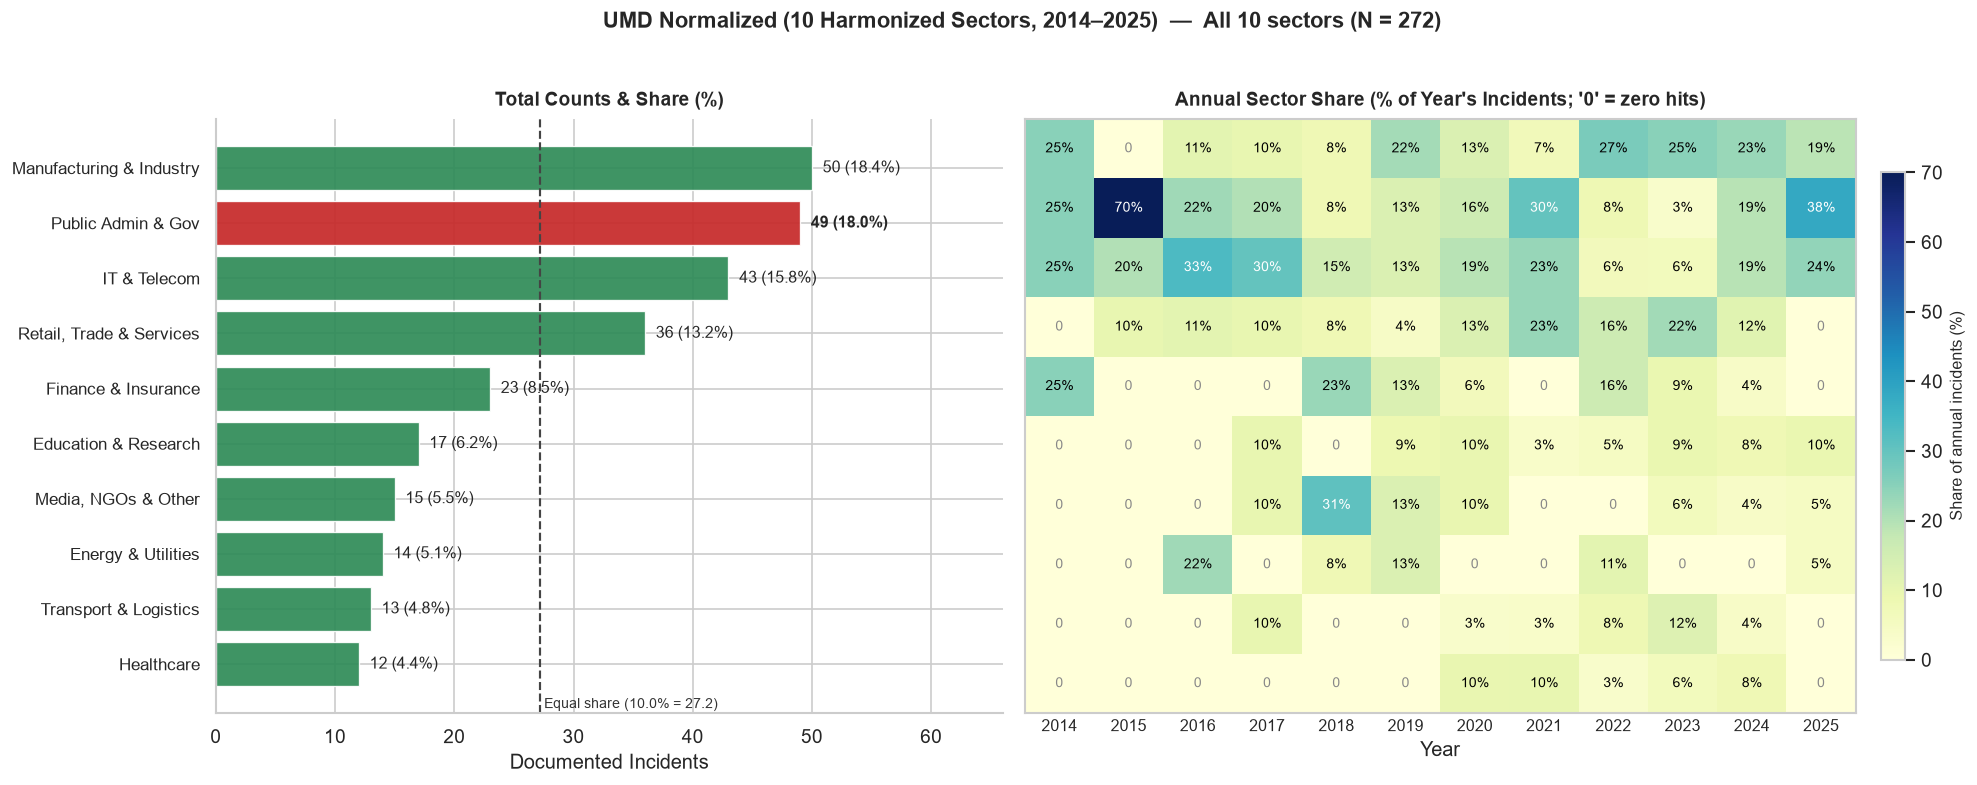

,Incidents,Share (%),Cumulative (%),Annual Mean,Annual Median (p50),Annual p25–p75,Annual Share % Median (p25–p75)
Sector,,,,,,,
Manufacturing & Industry,50,18.4,18.4,4.17,3.0,1.0 – 5.2,16.0% (9.4–23.6%)
Public Administration & Government,49,18.0,36.4,4.08,4.0,1.8 – 5.5,19.6% (11.8–26.2%)
IT & Telecommunications,43,15.8,52.2,3.58,3.0,2.0 – 5.0,19.7% (14.8–24.1%)
"Retail, Trade & Services",36,13.2,65.4,3.00,1.0,1.0 – 4.8,10.6% (6.9–13.6%)
Finance & Insurance,23,8.5,73.9,1.92,1.0,0.0 – 3.0,5.1% (0.0–13.8%)
Education & Research,17,6.2,80.1,1.42,1.5,0.0 – 2.2,6.2% (0.0–9.4%)
"Media, NGOs & Other",15,5.5,85.7,1.25,1.0,0.0 – 2.2,4.3% (0.0–9.8%)
Energy & Utilities,14,5.1,90.8,1.17,0.0,0.0 – 1.2,0.0% (0.0–8.5%)
Transportation & Logistics,13,4.8,95.6,1.08,0.5,0.0 – 1.0,1.6% (0.0–4.9%)


In [3]:
# Plot UMD incidents inside the normalized combined dataframe (10 standardized sectors)
_, _, _, umd_norm_tbl = build_sector_summary(umd_norm_known, "sector", YEARS_FULL)
_ = plot_sector_distribution(
    umd_norm_known,
    sector_col="sector",
    years=YEARS_FULL,
    title_prefix="UMD Normalized (10 Harmonized Sectors, 2014–2025)",
    bar_color="#2e8b57",
    label_map=SHORT_NORM,
)
display(umd_norm_tbl)

---

## 3. Complete Combined Dataset (`2014–2025` & Focused `2021–2025`) vs. UMD Views

Here we look at the **complete 4-source deduplicated German dataset** (`N = 1,592` sector-attributed incidents in `2014–2025`, of which **`1,465` (`92.0%`)** occur in `2021–2025` after *KonBriefing* and *Ransomware.live* scale up).

Why compare **all 3 datasets** side by side?
- Adding German leak-site and German incident tracking (*Ransomware.live* + *KonBriefing*) dramatically increases `Healthcare` (`4.4%` in UMD Normalized → **`9.2%`** in Combined) and reduces the relative weight of `IT & Telecommunications` (`15.8%` in UMD Normalized → **`6.3%`** in Combined).
- Meanwhile, **`Manufacturing & Industry` (`21.2%` in 2014–2025; `21.7%` in 2021–2025)** and **`Public Administration & Government` (`20.0%` in 2014–2025; `19.6%` in 2021–2025)** consistently take spots #1 and #2 regardless of source.

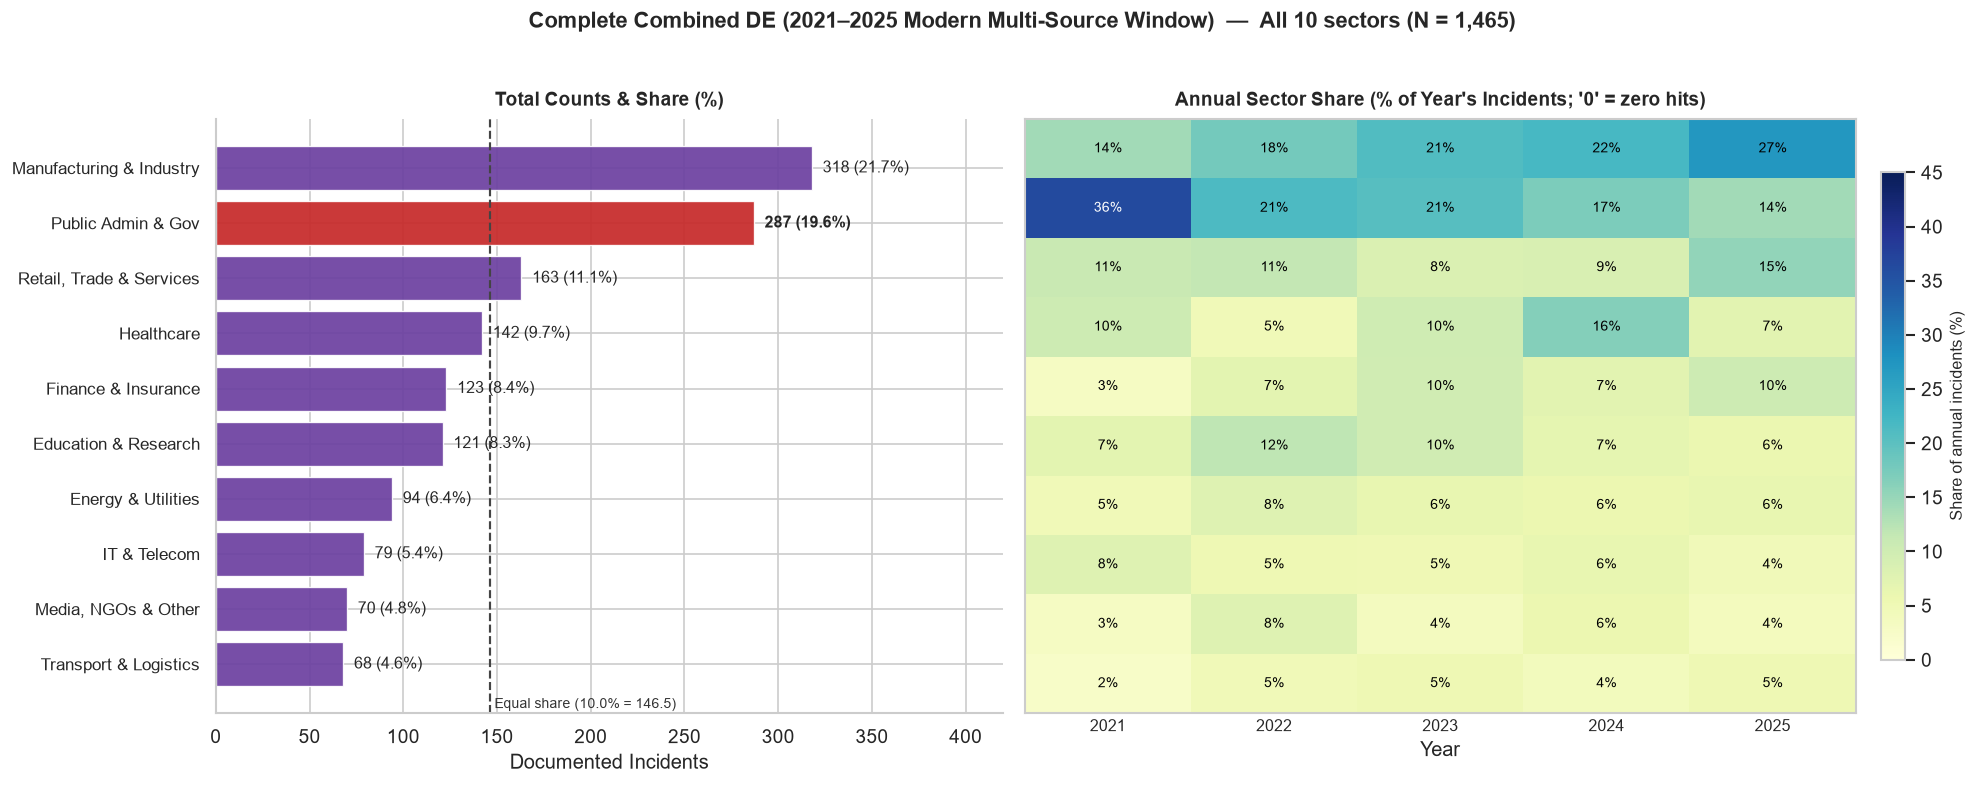

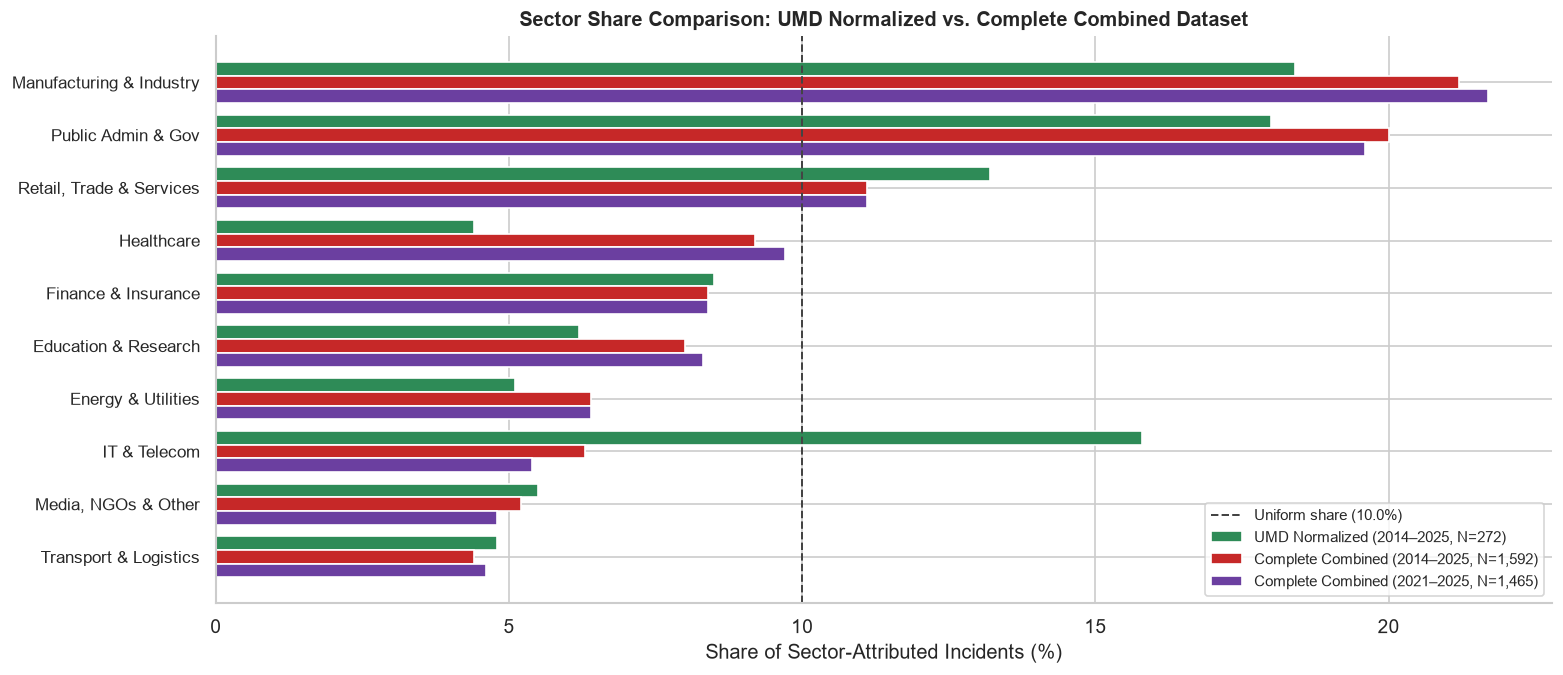

,UMD Norm % (2014–25),Combined % (2014–25),Combined % (2021–25),UMD Norm Median [p25–p75],Combined Median [p25–p75] (21–25)
Sector,,,,,
Manufacturing & Industry,18.4,21.2,21.7,16.0% (9.4–23.6%),21.0% (17.8–21.8%)
Public Administration & Government,18.0,20.0,19.6,19.6% (11.8–26.2%),20.5% (17.1–21.3%)
"Retail, Trade & Services",13.2,11.1,11.1,10.6% (6.9–13.6%),11.0% (8.7–11.5%)
Healthcare,4.4,9.2,9.7,0.0% (0.0–6.6%),10.1% (7.2–10.2%)
Finance & Insurance,8.5,8.4,8.4,5.1% (0.0–13.8%),7.4% (7.1–9.9%)
Education & Research,6.2,8.0,8.3,6.2% (0.0–9.4%),7.1% (6.7–9.9%)
Energy & Utilities,5.1,6.4,6.4,0.0% (0.0–8.5%),6.5% (5.7–6.5%)
IT & Telecommunications,15.8,6.3,5.4,19.7% (14.8–24.1%),5.1% (4.9–6.4%)
"Media, NGOs & Other",5.5,5.2,4.8,4.3% (0.0–9.8%),3.7% (3.6–5.7%)


In [4]:
# 1) Complete Combined dataset distribution across 2021-2025 (modern multi-source window)
_ = plot_sector_distribution(
    comb_known,
    sector_col="sector",
    years=YEARS_MODERN,
    title_prefix="Complete Combined DE (2021–2025 Modern Multi-Source Window)",
    bar_color="#6b3fa0",
    label_map=SHORT_NORM,
)

# 2) Direct comparison of sector shares (%) across the 10 normalized sectors + 2014-2025 vs 2021-2025
_, _, _, comb_full_tbl = build_sector_summary(comb_known, "sector", YEARS_FULL)
_, _, _, comb_mod_tbl = build_sector_summary(comb_known, "sector", YEARS_MODERN)

sec_order = list(comb_full_tbl.index)
share_comp = pd.DataFrame(
    {
        "UMD Norm % (2014–25)": umd_norm_tbl.reindex(sec_order)["Share (%)"],
        "Combined % (2014–25)": comb_full_tbl.reindex(sec_order)["Share (%)"],
        "Combined % (2021–25)": comb_mod_tbl.reindex(sec_order)["Share (%)"],
        "UMD Norm Median [p25–p75]": umd_norm_tbl.reindex(sec_order)["Annual Share % Median (p25–p75)"],
        "Combined Median [p25–p75] (21–25)": comb_mod_tbl.reindex(sec_order)["Annual Share % Median (p25–p75)"],
    }
)

fig, ax = plt.subplots(figsize=(13.2, 5.8))
y = np.arange(len(sec_order))
bh = 0.26
ax.barh(y - bh, share_comp["UMD Norm % (2014–25)"], height=bh, color="#2e8b57", label="UMD Normalized (2014–2025, N=272)")
ax.barh(y, share_comp["Combined % (2014–25)"], height=bh, color="#c62828", label="Complete Combined (2014–2025, N=1,592)")
ax.barh(y + bh, share_comp["Combined % (2021–25)"], height=bh, color="#6b3fa0", label="Complete Combined (2021–2025, N=1,465)")
ax.axvline(10.0, color="#444444", linestyle="--", linewidth=1.2, label="Uniform share (10.0%)")
ax.set_yticks(y)
ax.set_yticklabels([shorten(s, SHORT_NORM) for s in sec_order], fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("Share of Sector-Attributed Incidents (%)")
ax.set_title("Sector Share Comparison: UMD Normalized vs. Complete Combined Dataset")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", fontsize=9.2)
plt.tight_layout()
plt.show()

display(share_comp)

---

## 4. Are Sector Differences & `Public Administration` Counts Statistically Significant?

We are using **two clean layers** across all three datasets (`UMD Raw Top 10`, `UMD Normalized`, and `Complete Combined`) and both windows (`2014–2025` and `2021–2025`):

1. **Overall check across all 10 sectors:**
   - **Chi-Square Goodness-of-Fit (`chisquare`):** Tests whether total documented incidents are equally distributed (`10%` per sector) or concentrated in certain sectors.
   - **Friedman Test (`friedmanchisquare`):** Checks whether the sector ranking stays consistent year after year (accounting for overall multi-year growth).
2. **`Public Administration` vs. each other sector (one pairwise test: `Binomial Test + BH`):**
   - For each pair (`Public Administration` vs. `Sector Y`), we ask a direct question: *assuming both sectors were equally likely to be hit (`50/50`), how surprising is the observed split?*
   - We apply **Benjamini–Hochberg (`q_BH < 0.05`)** across the `9` comparisons to avoid false positives.

,N,Sectors,Years,Chi2 GoF,Chi2 p,Friedman Q,Friedman p,PA Sig. Pairs (Binom+BH)
UMD Raw Top 10 (2014–25),241,10,12,81.28,0.0,31.91,0.000206,6/9
UMD Normalized (2014–25),272,10,12,80.87,0.0,41.96,0.000003,6/9
Complete Combined (2014–25),1592,10,12,499.68,0.0,52.29,0.0,8/9
UMD Raw Top 10 (2021–25),153,10,5,68.5,0.0,17.29,0.044301,6/9
UMD Normalized (2021–25),172,10,5,61.14,0.0,18.11,0.033883,5/9
Complete Combined (2021–25),1465,10,5,477.64,0.0,33.99,0.00009,8/9


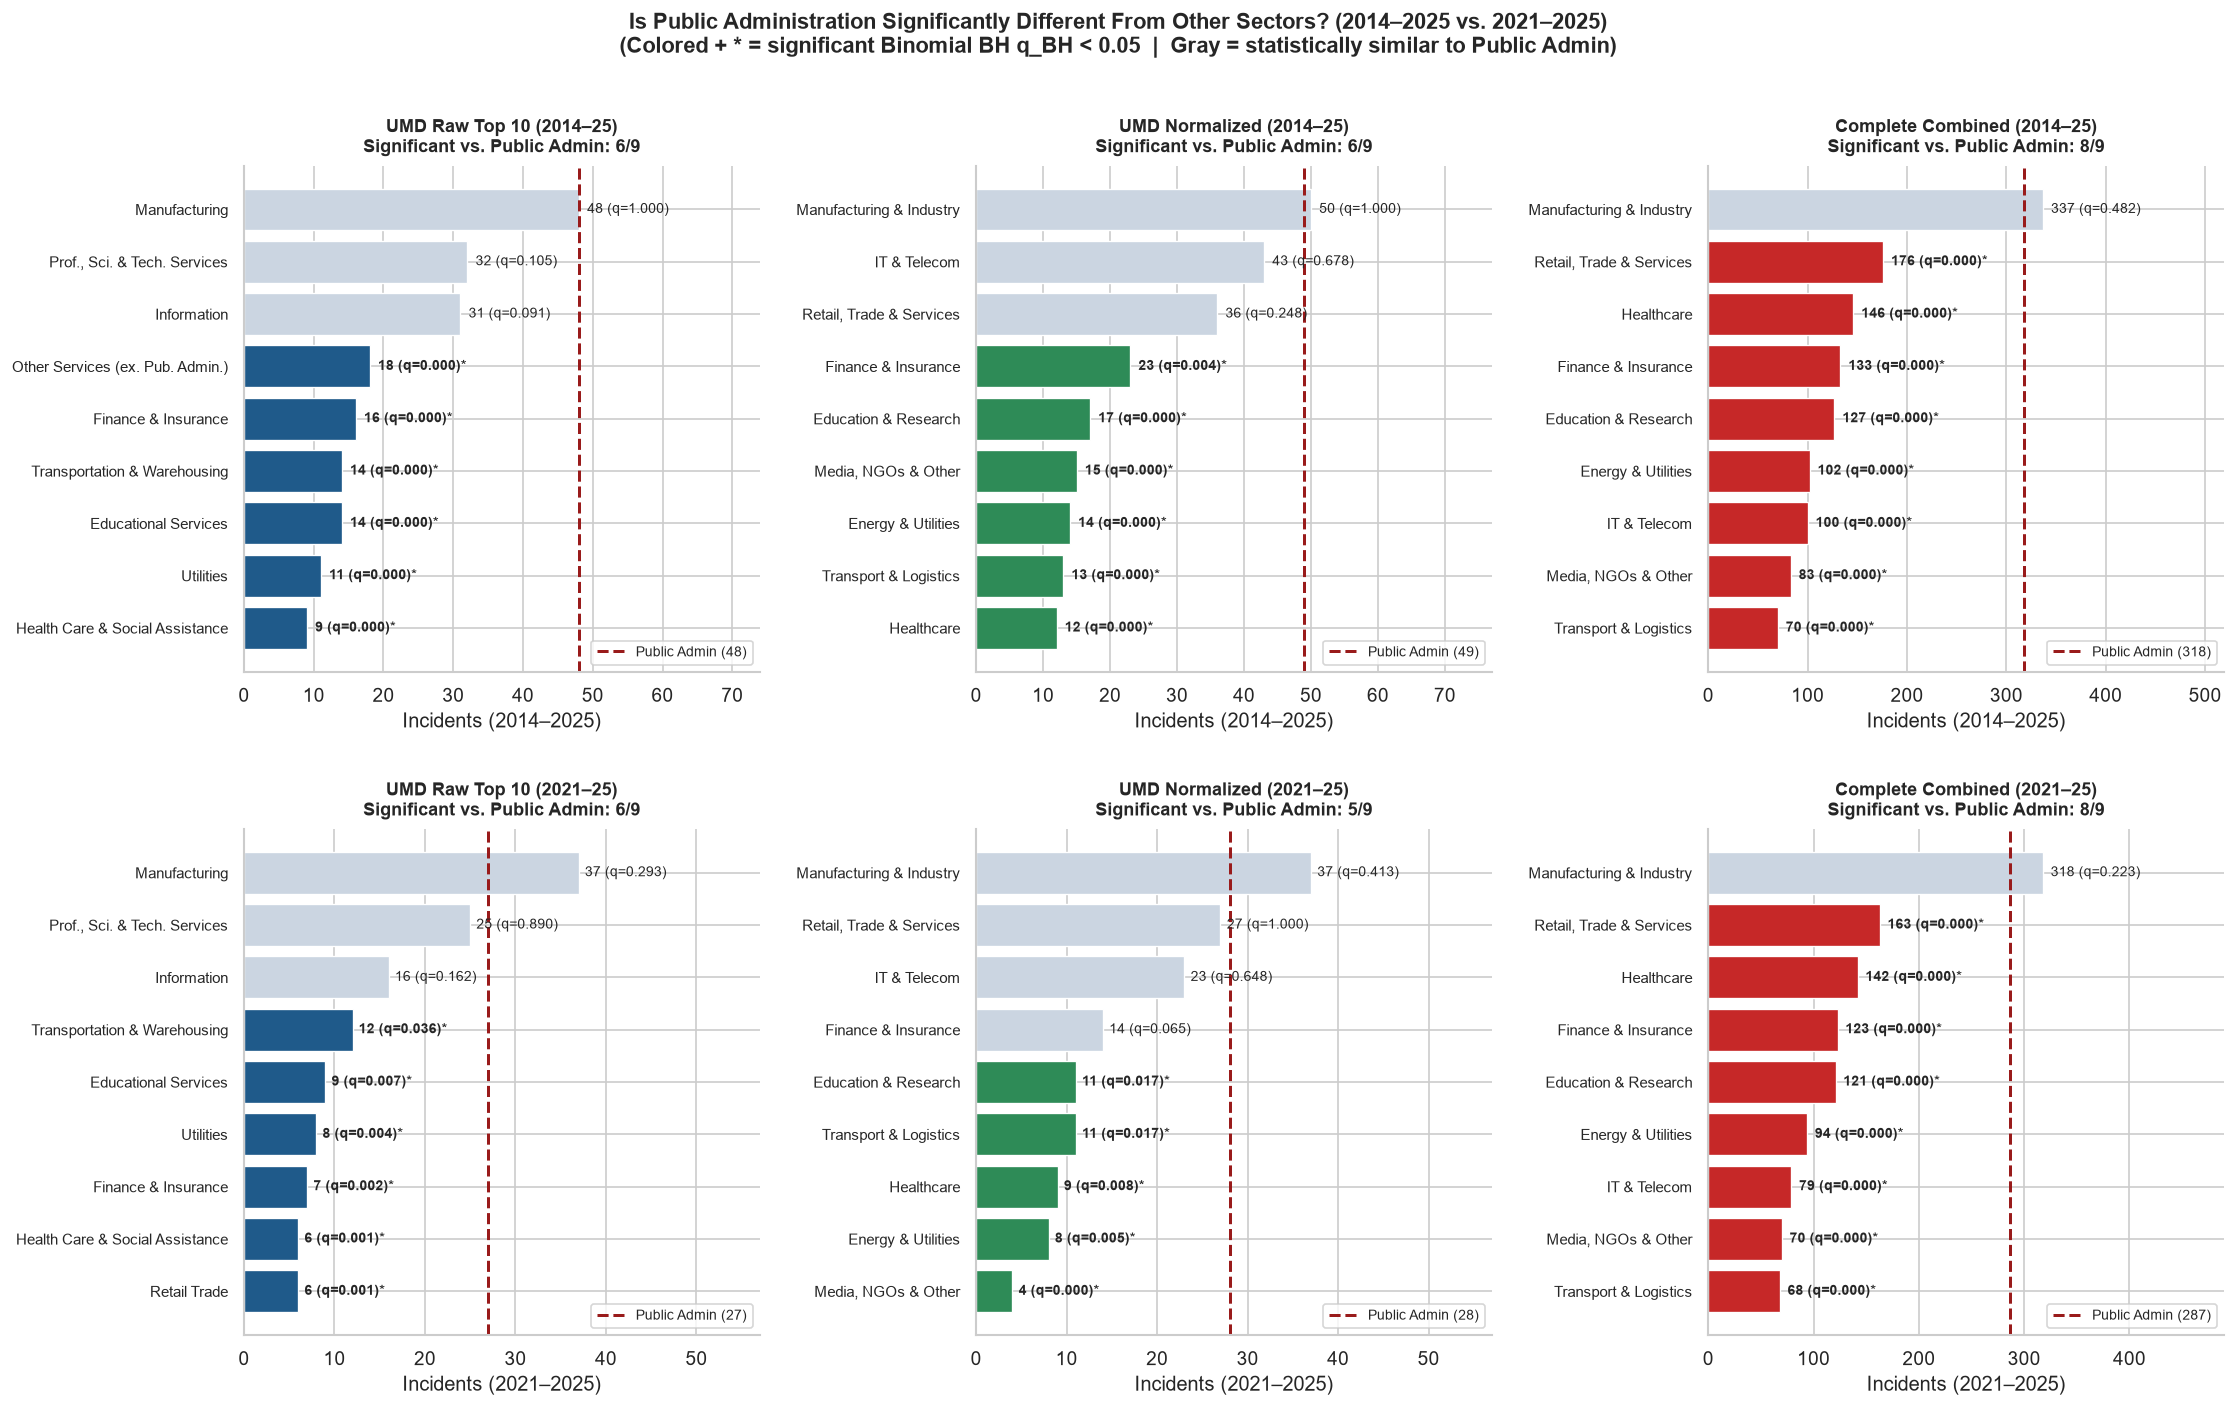

Complete Combined (2021–2025) — Public Administration vs. every other sector:


,Other Sector,PA Count,Other Count,Ratio (PA / Other),Binom p_raw,Binom q_BH,Significant (q_BH < 0.05)
0,Manufacturing & Industry,287,318,0.90,0.2226,0.2226,False
1,"Retail, Trade & Services",287,163,1.76,0.0000,0.0000,True
2,Healthcare,287,142,2.02,0.0000,0.0000,True
3,Finance & Insurance,287,123,2.33,0.0000,0.0000,True
4,Education & Research,287,121,2.37,0.0000,0.0000,True
5,Energy & Utilities,287,94,3.05,0.0000,0.0000,True
6,IT & Telecommunications,287,79,3.63,0.0000,0.0000,True
7,"Media, NGOs & Other",287,70,4.10,0.0000,0.0000,True
8,Transportation & Logistics,287,68,4.22,0.0000,0.0000,True


In [5]:
def analyze_sectors(df, sector_col, years, top_n=None, label_map=None):
    """Run omnibus checks (Chi2 GoF + Friedman) and PA-vs-others Binomial tests with BH correction."""
    sub = df[df["year"].isin(years)].copy()
    vc_all = sub[sector_col].value_counts()
    sectors = list(vc_all.head(top_n).index) if (top_n and len(vc_all) > top_n) else list(vc_all.index)
    vc, piv_cnt, _, _ = build_sector_summary(df, sector_col, years, sectors=sectors)

    # 1) Omnibus checks across all sectors
    chi_stat, chi_p = chisquare(vc.values)
    fr_stat, fr_p = friedmanchisquare(*[piv_cnt[s].values for s in sectors])

    # 2) Public Administration vs. every other sector individually (Binomial test + BH)
    pa_col = [s for s in sectors if s.startswith("Public Administration")][0]
    pa_cnt = int(vc[pa_col])
    others = [s for s in sectors if s != pa_col]

    p_bin = [binomtest(pa_cnt, pa_cnt + int(vc[o]), 0.5).pvalue for o in others]
    q_bin = false_discovery_control(np.array(p_bin), method="bh")

    pa_rows = []
    for idx, o in enumerate(others):
        o_cnt = int(vc[o])
        pa_rows.append(
            {
                "Other Sector": o,
                "Other Short": shorten(o, label_map),
                "PA Count": pa_cnt,
                "Other Count": o_cnt,
                "Ratio (PA / Other)": round(pa_cnt / max(o_cnt, 1), 2),
                "Binom p_raw": p_bin[idx],
                "Binom q_BH": q_bin[idx],
                "Significant (q_BH < 0.05)": bool(q_bin[idx] < 0.05),
            }
        )
    pa_df = pd.DataFrame(pa_rows)

    omnibus = {
        "N": int(vc.sum()),
        "Sectors": len(sectors),
        "Years": len(years),
        "Chi2 GoF": round(float(chi_stat), 2),
        "Chi2 p": float(chi_p),
        "Friedman Q": round(float(fr_stat), 2),
        "Friedman p": float(fr_p),
        "PA Sig. Pairs (Binom+BH)": f"{int(pa_df['Significant (q_BH < 0.05)'].sum())}/{len(others)}",
    }
    return {"omnibus": omnibus, "pa_df": pa_df, "vc": vc, "pa_col": pa_col, "sectors": sectors}


specs = [
    ("UMD Raw Top 10 (2014–25)", umd_raw_known, "industry", YEARS_FULL, 10, SHORT_NAICS),
    ("UMD Normalized (2014–25)", umd_norm_known, "sector", YEARS_FULL, None, SHORT_NORM),
    ("Complete Combined (2014–25)", comb_known, "sector", YEARS_FULL, None, SHORT_NORM),
    ("UMD Raw Top 10 (2021–25)", umd_raw_known, "industry", YEARS_MODERN, 10, SHORT_NAICS),
    ("UMD Normalized (2021–25)", umd_norm_known, "sector", YEARS_MODERN, None, SHORT_NORM),
    ("Complete Combined (2021–25)", comb_known, "sector", YEARS_MODERN, None, SHORT_NORM),
]

results = {name: analyze_sectors(df, col, yrs, top_n=tn, label_map=lm) for name, df, col, yrs, tn, lm in specs}

omni_df = pd.DataFrame({k: v["omnibus"] for k, v in results.items()}).T
display(omni_df)

# Visualize Public Administration vs. every other sector across ALL 6 dataset x window combinations (2 rows x 3 cols)
fig, axes = plt.subplots(2, 3, figsize=(18.8, 11.6))
grid_specs = [
    [
        ("UMD Raw Top 10 (2014–25)", "#1f5a8a", "2014–2025"),
        ("UMD Normalized (2014–25)", "#2e8b57", "2014–2025"),
        ("Complete Combined (2014–25)", "#c62828", "2014–2025"),
    ],
    [
        ("UMD Raw Top 10 (2021–25)", "#1f5a8a", "2021–2025"),
        ("UMD Normalized (2021–25)", "#2e8b57", "2021–2025"),
        ("Complete Combined (2021–25)", "#c62828", "2021–2025"),
    ],
]

for r_idx, row_items in enumerate(grid_specs):
    for c_idx, (key, base_col, yr_lbl) in enumerate(row_items):
        ax = axes[r_idx, c_idx]
        res = results[key]
        pa_df = res["pa_df"]
        pa_cnt = int(res["vc"][res["pa_col"]])
        y = np.arange(len(pa_df))

        # Simple two-color encoding: colored = significantly different from PA (q_BH < 0.05), gray = not sig.
        bar_cols = [base_col if sig else "#cbd5e1" for sig in pa_df["Significant (q_BH < 0.05)"]]
        ax.barh(y, pa_df["Other Count"], color=bar_cols, edgecolor="white", linewidth=0.8)
        ax.axvline(pa_cnt, color="#991b1b", linestyle="--", linewidth=1.8, label=f"Public Admin ({pa_cnt})")
        ax.set_yticks(y)
        ax.set_yticklabels(pa_df["Other Short"], fontsize=9.2)
        ax.invert_yaxis()
        ax.set_xlim(0, max(pa_cnt, int(pa_df["Other Count"].max())) * 1.54)

        for idx, row in pa_df.iterrows():
            is_sig = bool(row["Significant (q_BH < 0.05)"])
            ax.text(
                row["Other Count"] + max(pa_cnt, 10) * 0.025,
                idx,
                f"{int(row['Other Count'])} (q={row['Binom q_BH']:.3f}){'*' if is_sig else ''}",
                va="center",
                fontsize=8.2,
                fontweight="bold" if is_sig else "normal",
            )

        ax.set_xlabel(f"Incidents ({yr_lbl})")
        ax.set_title(
            f"{key}\nSignificant vs. Public Admin: {res['omnibus']['PA Sig. Pairs (Binom+BH)']}",
            fontsize=11.0,
            pad=8,
        )
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="lower right", fontsize=8.4)

fig.suptitle(
    "Is Public Administration Significantly Different From Other Sectors? (2014–2025 vs. 2021–2025)\n"
    "(Colored + * = significant Binomial BH q_BH < 0.05  |  Gray = statistically similar to Public Admin)",
    fontsize=13.2,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout(h_pad=2.4, w_pad=1.8)
plt.show()

print("Complete Combined (2021–2025) — Public Administration vs. every other sector:")
display(
    results["Complete Combined (2021–25)"]["pa_df"][
        ["Other Sector", "PA Count", "Other Count", "Ratio (PA / Other)", "Binom p_raw", "Binom q_BH", "Significant (q_BH < 0.05)"]
    ].round(4)
)

---

## 5. All-Pairs Sector Differences (`10 × 10` with BH) Across Both Time Windows (`2014–2025` & `2021–2025`)

Using the **same single Binomial + BH method** across all `45` unique pairs of sectors (`m = 45`, `q_BH < 0.05`), we compare all `6` views (**`3 datasets × 2 time windows`**):

- **UMD datasets (`UMD Raw Top 10` and `UMD Normalized`):** In both `2014–2025` and `2021–2025`, the top 3–4 sectors (`Manufacturing`, `Public Administration`, `IT / Information`, `Prof. / Retail Services`) sit close enough together that their pairwise differences are **not statistically significant**, while clearly outpacing the lower 5–6 sectors (`20 / 45` and `23 / 45` significant pairs in `2014–2025`; `17 / 45` and `19 / 45` in `2021–2025`).
- **Complete Combined dataset:** Because multi-source tracking gives ~`6×` more incidents (`N = 1,592` in `2014–2025`; `N = 1,465` in `2021–2025`), statistical power is much higher: **`33 / 45`** (`2014–25`) and **`32 / 45`** (`2021–25`) pairs are separated cleanly, leaving only tight neighbors (`Manufacturing & Industry` vs. `Public Administration & Government`, or adjacent mid-tier sectors) statistically tied.

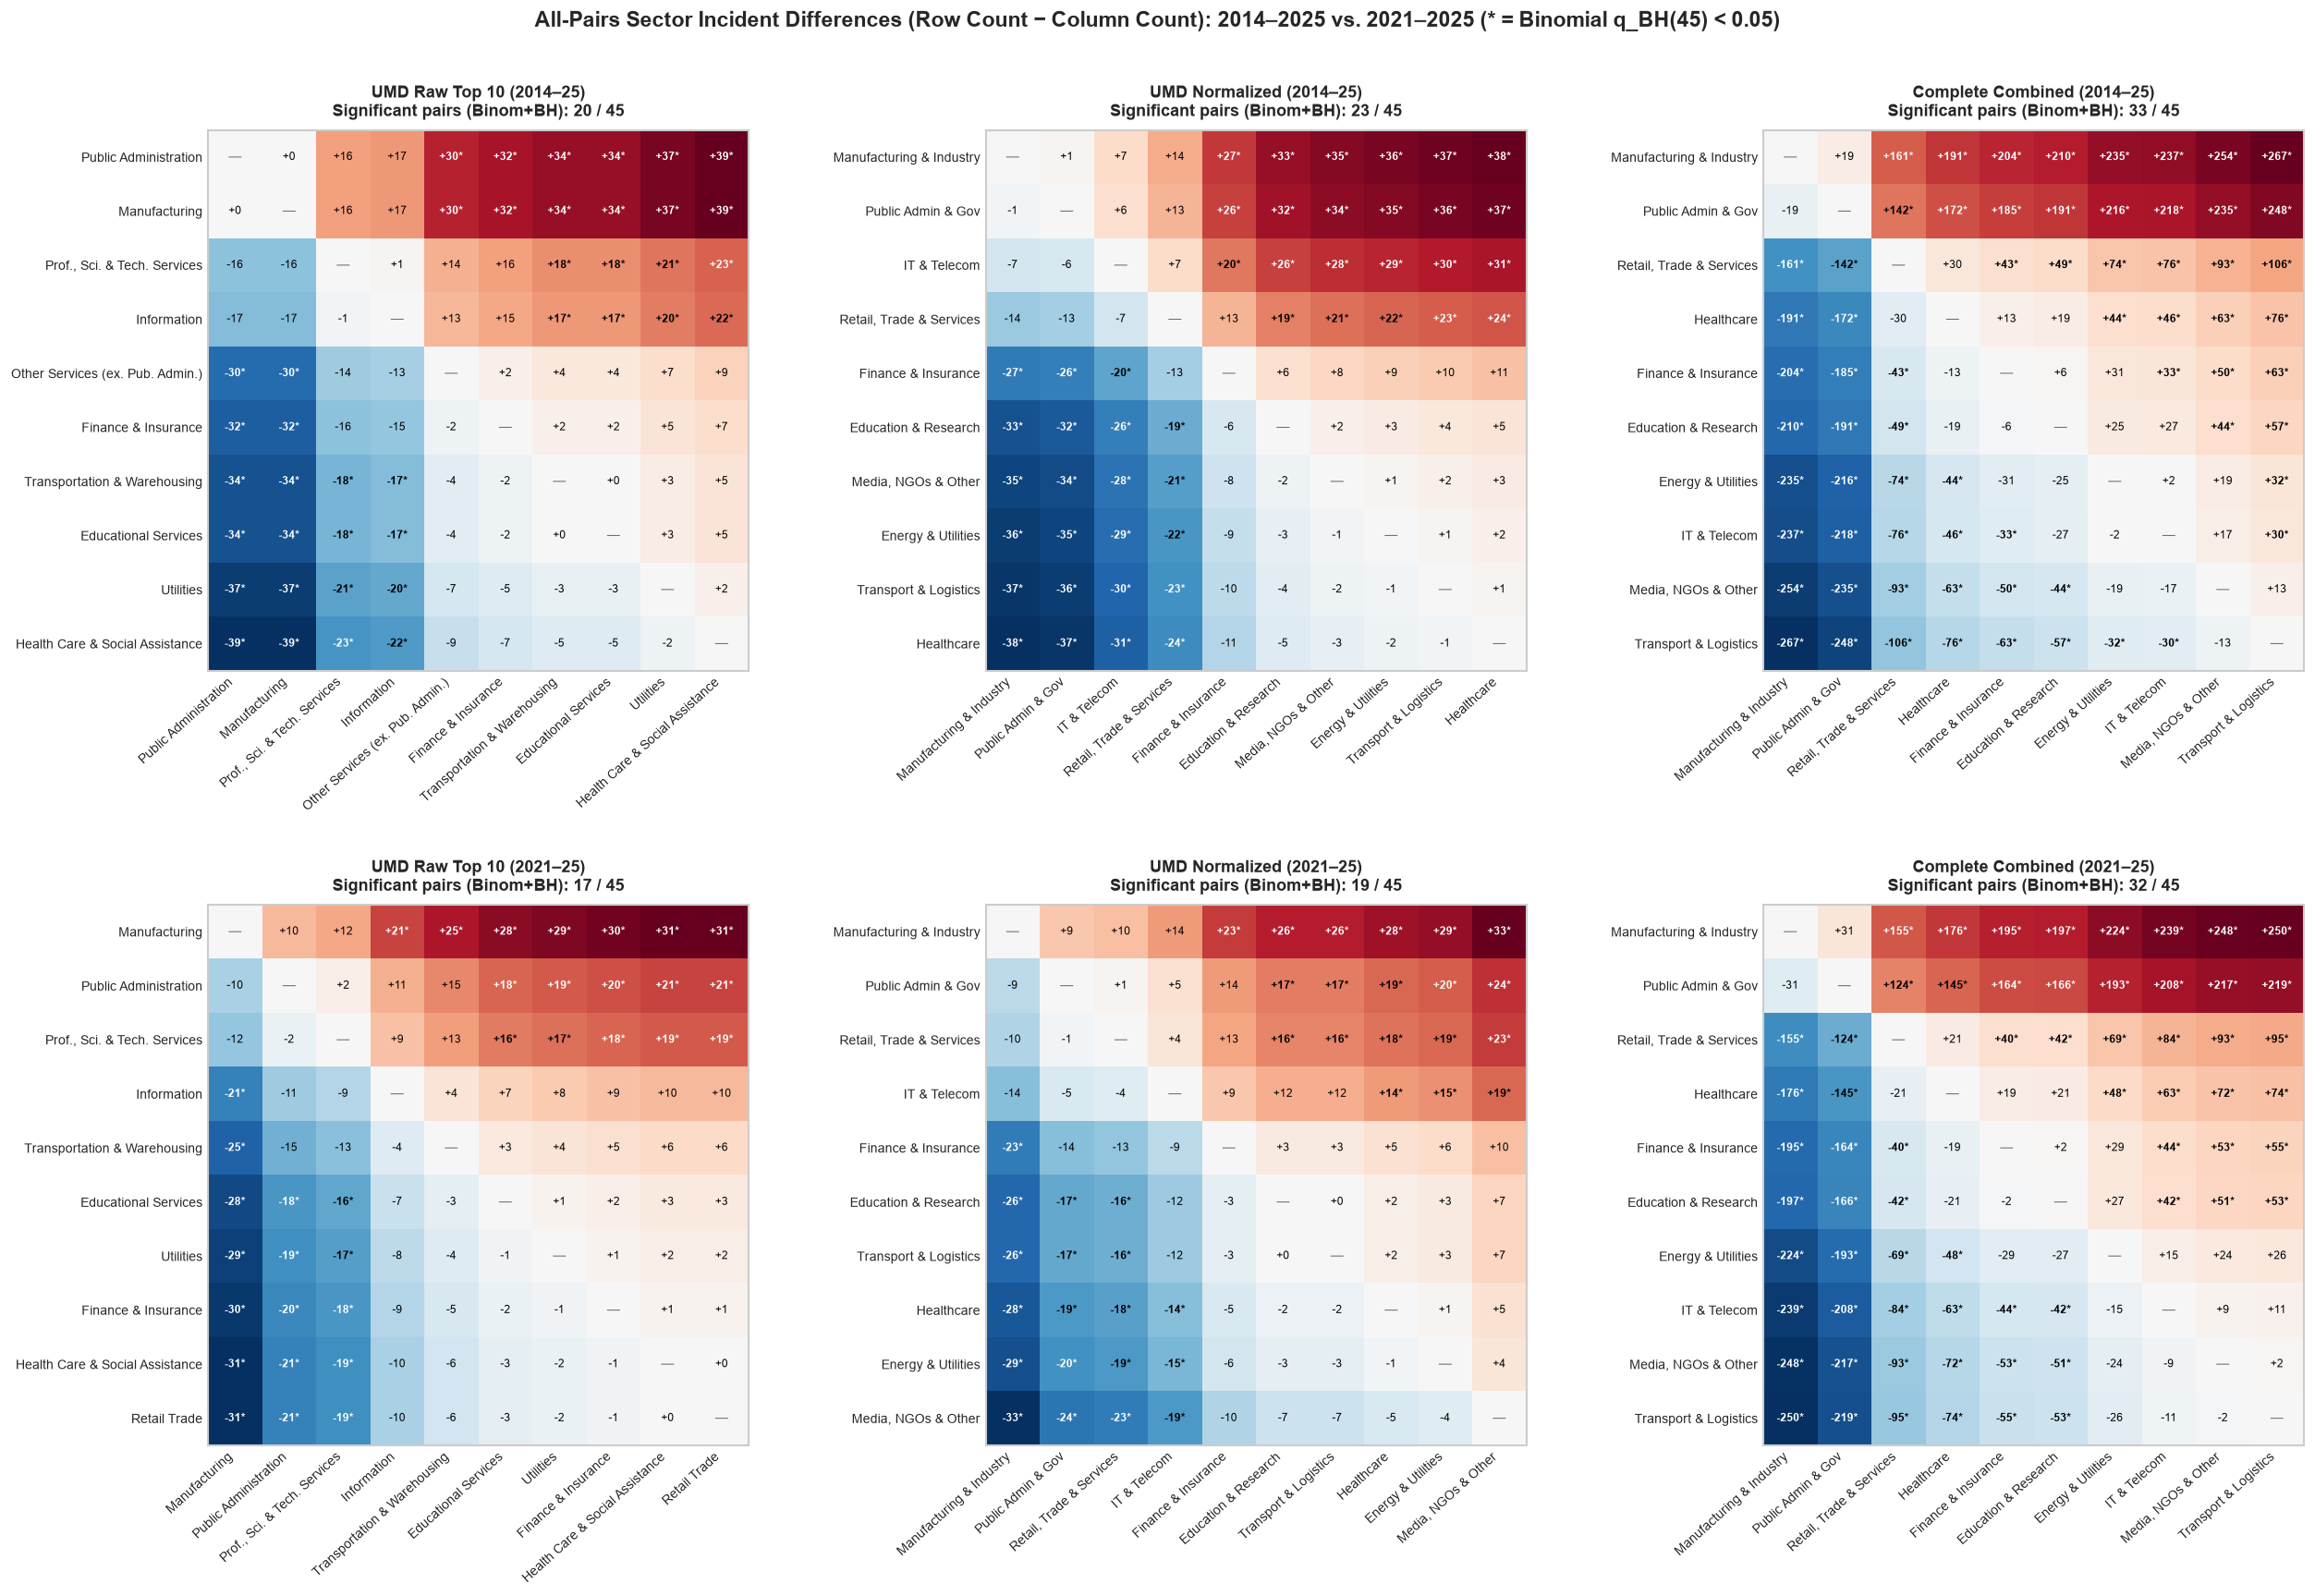

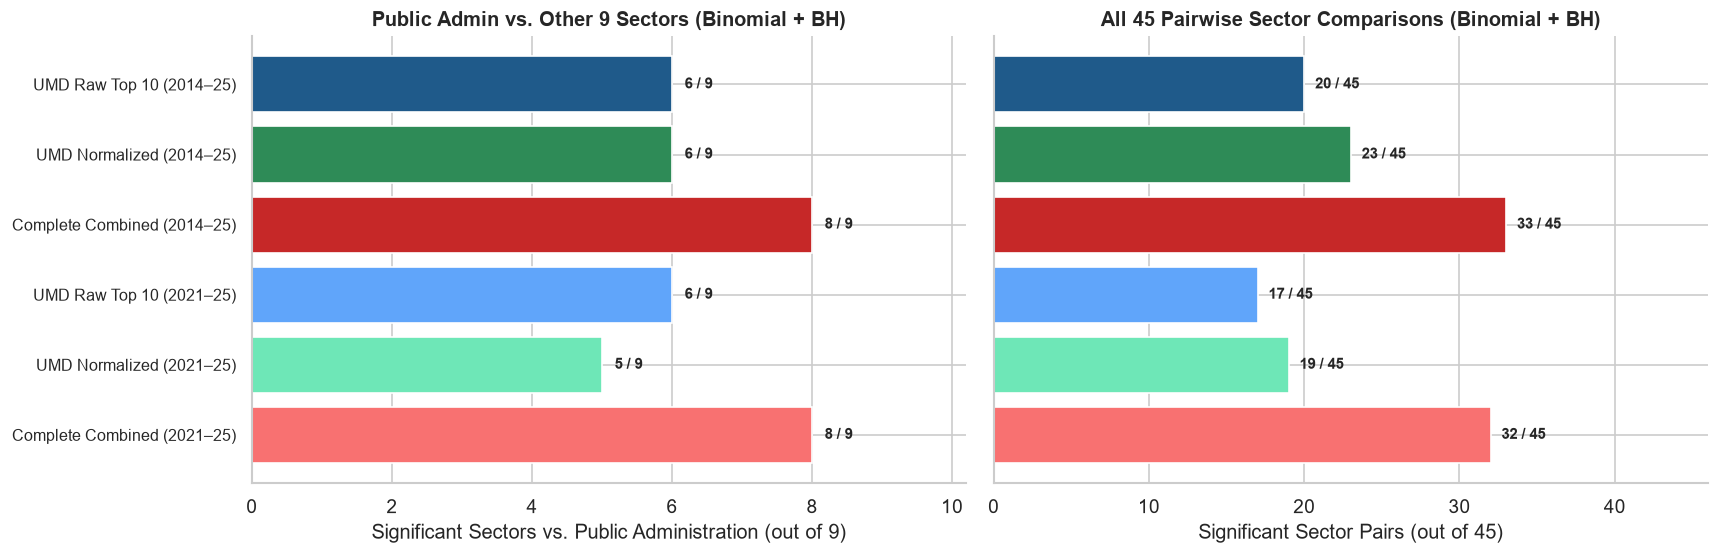

,Total Incidents (N),PA vs Others Sig. (out of 9),All Pairs Sig. (out of 45)
Dataset & Window,,,
UMD Raw Top 10 (2014–25),241,6,20
UMD Normalized (2014–25),272,6,23
Complete Combined (2014–25),1592,8,33
UMD Raw Top 10 (2021–25),153,6,17
UMD Normalized (2021–25),172,5,19
Complete Combined (2021–25),1465,8,32


In [6]:
def all_pairs_binomial_bh(res_dict, label_map=None):
    """Compute 10x10 pairwise count differences (row - col) and BH q-values across 45 pairs."""
    vc = res_dict["vc"]
    sectors = res_dict["sectors"]
    k = len(sectors)
    short_names = [shorten(s, label_map) for s in sectors]

    diff_mat = np.zeros((k, k), dtype=int)
    p_bin_list, coords = [], []
    for i in range(k):
        for j in range(k):
            diff_mat[i, j] = int(vc[sectors[i]]) - int(vc[sectors[j]])
            if i < j:
                ci, cj = int(vc[sectors[i]]), int(vc[sectors[j]])
                p_bin_list.append(binomtest(ci, ci + cj, 0.5).pvalue if (ci + cj) > 0 else 1.0)
                coords.append((i, j))

    q_bin = false_discovery_control(np.array(p_bin_list), method="bh")
    q_bin_mat = np.ones((k, k), dtype=float)
    for (i, j), qb in zip(coords, q_bin):
        q_bin_mat[i, j] = q_bin_mat[j, i] = qb

    return {
        "labels": short_names,
        "diff": diff_mat,
        "q_bin": q_bin_mat,
        "sig_bin_45": int((q_bin < 0.05).sum()),
        "m_pairs": len(coords),
    }


all_pair_stats = {
    name: all_pairs_binomial_bh(results[name], label_map=lm)
    for name, _, _, _, _, lm in specs
}

# 1) 2x3 All-Pairs 10x10 Sector Difference Matrices (Top row: 2014-2025 | Bottom row: 2021-2025)
fig, axes = plt.subplots(2, 3, figsize=(21.5, 14.2))
mat_grid = [
    ["UMD Raw Top 10 (2014–25)", "UMD Normalized (2014–25)", "Complete Combined (2014–25)"],
    ["UMD Raw Top 10 (2021–25)", "UMD Normalized (2021–25)", "Complete Combined (2021–25)"],
]

for r_idx, row_names in enumerate(mat_grid):
    for c_idx, mname in enumerate(row_names):
        ax = axes[r_idx, c_idx]
        pm = all_pair_stats[mname]
        k = len(pm["labels"])
        vmax = max(1, int(np.abs(pm["diff"]).max()))
        ax.grid(False)
        ax.imshow(pm["diff"], cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        ax.set_xticks(range(k))
        ax.set_xticklabels(pm["labels"], rotation=42, ha="right", fontsize=8.2)
        ax.set_yticks(range(k))
        ax.set_yticklabels(pm["labels"], fontsize=8.4)

        for i in range(k):
            for j in range(k):
                if i == j:
                    ax.text(j, i, "—", ha="center", va="center", fontsize=8.2, color="#666666")
                else:
                    dval = pm["diff"][i, j]
                    is_sig = pm["q_bin"][i, j] < 0.05
                    ax.text(
                        j,
                        i,
                        f"{dval:+d}{'*' if is_sig else ''}",
                        ha="center",
                        va="center",
                        fontsize=7.2,
                        fontweight="bold" if is_sig else "normal",
                        color="white" if abs(dval) > vmax * 0.58 else "black",
                    )
        ax.set_title(
            f"{mname}\nSignificant pairs (Binom+BH): {pm['sig_bin_45']} / {pm['m_pairs']}",
            fontsize=11.0,
            pad=9,
        )
        ax.tick_params(length=0)

fig.suptitle(
    "All-Pairs Sector Incident Differences (Row Count − Column Count): 2014–2025 vs. 2021–2025 (* = Binomial q_BH(45) < 0.05)",
    fontsize=13.5,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout(h_pad=2.8, w_pad=1.8)
plt.show()

# 2) Simple summary comparison across the 3 datasets and 2 windows
comp_rows = []
for name in results:
    pm = all_pair_stats[name]
    pa_sig = int(results[name]["pa_df"]["Significant (q_BH < 0.05)"].sum())
    comp_rows.append(
        {
            "Dataset & Window": name,
            "Total Incidents (N)": results[name]["omnibus"]["N"],
            "PA vs Others Sig. (out of 9)": pa_sig,
            "All Pairs Sig. (out of 45)": pm["sig_bin_45"],
        }
    )
comp_sig_df = pd.DataFrame(comp_rows).set_index("Dataset & Window")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 4.8))
y = np.arange(len(comp_sig_df))
colors_ds = ["#1f5a8a", "#2e8b57", "#c62828", "#60a5fa", "#6ee7b7", "#f87171"]

ax1.barh(y, comp_sig_df["PA vs Others Sig. (out of 9)"], color=colors_ds, edgecolor="white")
ax1.set_yticks(y)
ax1.set_yticklabels(comp_sig_df.index, fontsize=9.8)
ax1.invert_yaxis()
ax1.set_xlim(0, 10.2)
ax1.set_xlabel("Significant Sectors vs. Public Administration (out of 9)")
ax1.set_title("Public Admin vs. Other 9 Sectors (Binomial + BH)")
for i, v in enumerate(comp_sig_df["PA vs Others Sig. (out of 9)"]):
    ax1.text(v + 0.18, i, f"{int(v)} / 9", va="center", fontsize=9.2, fontweight="bold")
ax1.spines[["top", "right"]].set_visible(False)

ax2.barh(y, comp_sig_df["All Pairs Sig. (out of 45)"], color=colors_ds, edgecolor="white")
ax2.set_yticks(y)
ax2.set_yticklabels(["" for _ in comp_sig_df.index])
ax2.invert_yaxis()
ax2.set_xlim(0, 46)
ax2.set_xlabel("Significant Sector Pairs (out of 45)")
ax2.set_title("All 45 Pairwise Sector Comparisons (Binomial + BH)")
for i, v in enumerate(comp_sig_df["All Pairs Sig. (out of 45)"]):
    ax2.text(v + 0.7, i, f"{int(v)} / 45", va="center", fontsize=9.2, fontweight="bold")
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()
display(comp_sig_df)